# Tasks for laboratory assignment 3

In [1]:
# imports section

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.feature_extraction.text import TfidfVectorizer

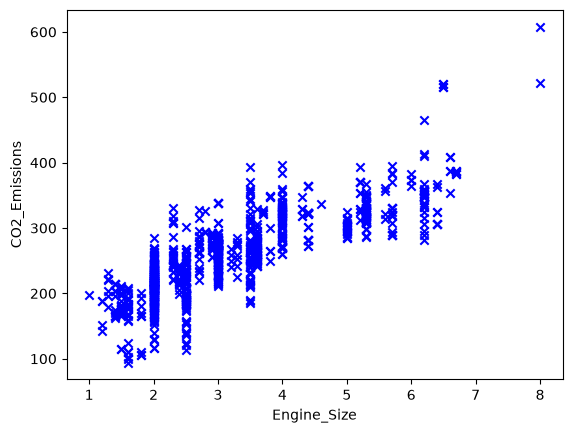

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    return pd.read_csv(file_path) 

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Linear Regression RMSE: 37.97311599331792 | R^2 Score: 0.6420
Quadratic Regression RMSE: 37.35316861323983 | R^2 Score: 0.6536


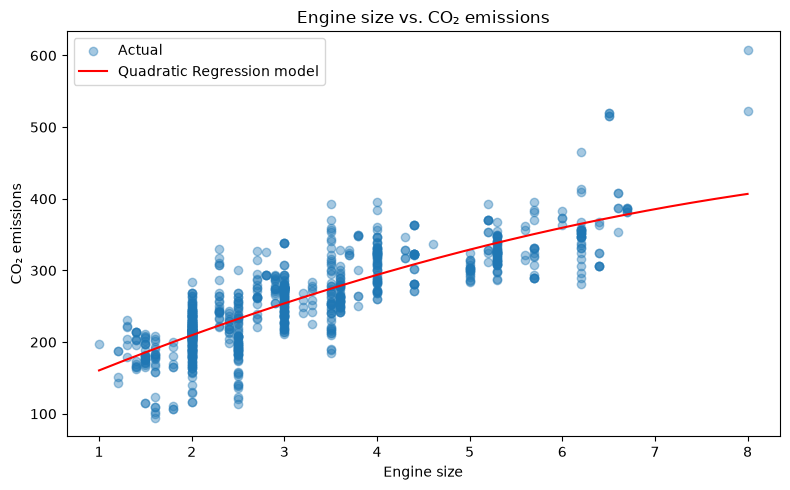

In [4]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[['Engine_Size']]
    y = data['CO2_Emissions']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    models = {
        "Linear Regression": LinearRegression(),
        "Quadratic Regression": make_pipeline(
            PolynomialFeatures(degree=2), 
            LinearRegression()
        ),
    }

    rmse_scores = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        rmse_scores[name] = rmse
        print(
            f"{name} RMSE: {rmse}"
            f" | R^2 Score: {r2_score(y_test, predictions):.4f}"
            )

    best_name = min(rmse_scores, key=rmse_scores.get)
    best_model = models[best_name]
    best_model.fit(X, y)

    x_plot = pd.DataFrame({
        "Engine_Size": np.linspace(X["Engine_Size"].min(),
                                   X["Engine_Size"].max(), 200)
    })

    plt.figure(figsize=(8, 5))
    plt.scatter(X["Engine_Size"], y, alpha=0.4, label="Actual")
    plt.plot(
        x_plot["Engine_Size"],
        best_model.predict(x_plot),
        color="red",
        label=f"{best_name} model",
    )
    plt.xlabel("Engine size")
    plt.ylabel("CO₂ emissions")
    plt.title("Engine size vs. CO₂ emissions")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return best_model


data = extract_texts_from_file('resources/CO2_emission.csv')
co2_model = CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Linear: RMSE=12.22, R²=-0.575
Quadratic: RMSE=3.86, R²=0.843


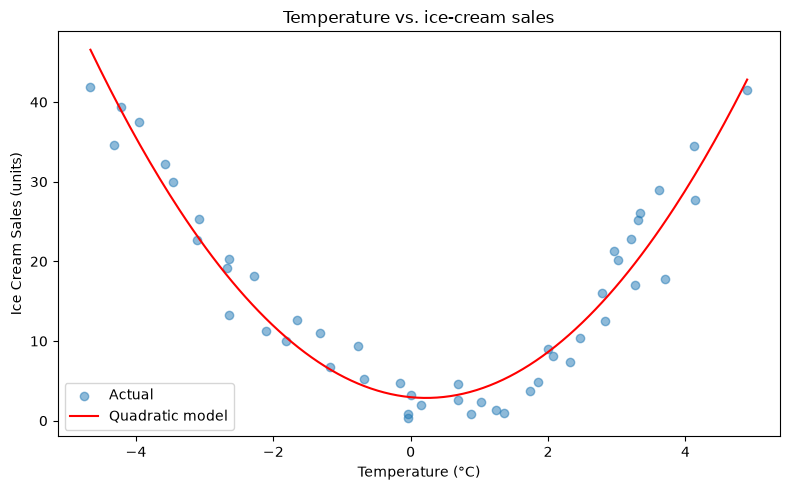

In [5]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    x_column = "Temperature (°C)"
    y_column = "Ice Cream Sales (units)"

    X = data[[x_column]]
    y = data[y_column]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    models = {
        "Linear": LinearRegression(),
        "Quadratic": make_pipeline(
            PolynomialFeatures(degree=2, include_bias=False),
            LinearRegression(),
        ),
    }

    rmse_scores = {}
    for name, candidate in models.items():
        candidate.fit(X_train, y_train)
        predictions = candidate.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        rmse_scores[name] = rmse
        print(f"{name}: RMSE={rmse:.2f}, R²={r2_score(y_test, predictions):.3f}")

    best_name = min(rmse_scores, key=rmse_scores.get)
    best_model = models[best_name]
    best_model.fit(X, y)

    x_plot = pd.DataFrame({
        x_column: np.linspace(X[x_column].min(), X[x_column].max(), 200)
    })

    plt.figure(figsize=(8, 5))
    plt.scatter(X[x_column], y, alpha=0.5, label="Actual")
    plt.plot(
        x_plot[x_column],
        best_model.predict(x_plot),
        color="red",
        label=f"{best_name} model",
    )
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.title("Temperature vs. ice-cream sales")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return best_model

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_model = ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

PowerConsumption_Zone1: RMSE=6002.03, R²=0.053
PowerConsumption_Zone2: RMSE=6830.93, R²=-0.552
PowerConsumption_Zone3: RMSE=6282.69, R²=-2.627


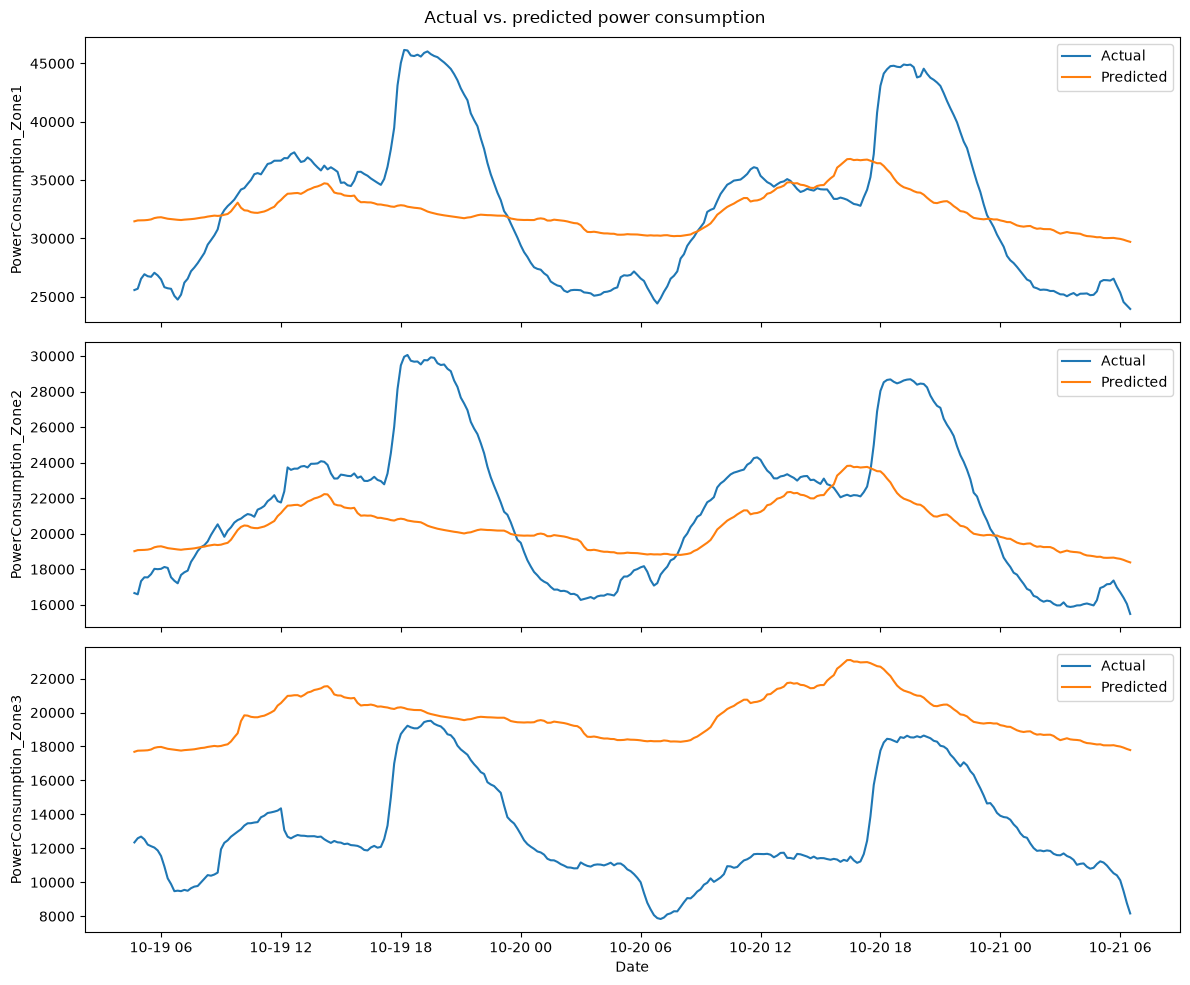

In [6]:
def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. 
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    df = data.copy()
    df["Datetime"] = pd.to_datetime(df["Datetime"])
    df = df.sort_values("Datetime").reset_index(drop=True)

    feature_columns = ["Temperature", "Humidity", "WindSpeed"]
    target_columns = [
        "PowerConsumption_Zone1",
        "PowerConsumption_Zone2",
        "PowerConsumption_Zone3",
    ]

    X = df[feature_columns]
    y = df[target_columns]

    split_index = int(len(df) * 0.8)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    dates = df["Datetime"].iloc[split_index:]
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    for i, target in enumerate(target_columns):
        actual = y_test[target].to_numpy()
        predicted = predictions[:, i]
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        r2 = r2_score(actual, predicted)
        print(f"{target}: RMSE={rmse:.2f}, R²={r2:.3f}")

        plot_count = min(300, len(actual))
        axes[i].plot(dates.iloc[:plot_count], actual[:plot_count], label="Actual")
        axes[i].plot(
            dates.iloc[:plot_count], predicted[:plot_count], label="Predicted"
        )
        axes[i].set_ylabel(target)
        axes[i].legend()

    axes[-1].set_xlabel("Date")
    fig.suptitle("Actual vs. predicted power consumption")
    fig.tight_layout()
    plt.show()

    return model


data = extract_texts_from_file('resources/powerconsumption.csv')
power_model = power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Accuracy: 0.803
              precision    recall  f1-score   support

  Lower risk       0.86      0.68      0.76        28
 Higher risk       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



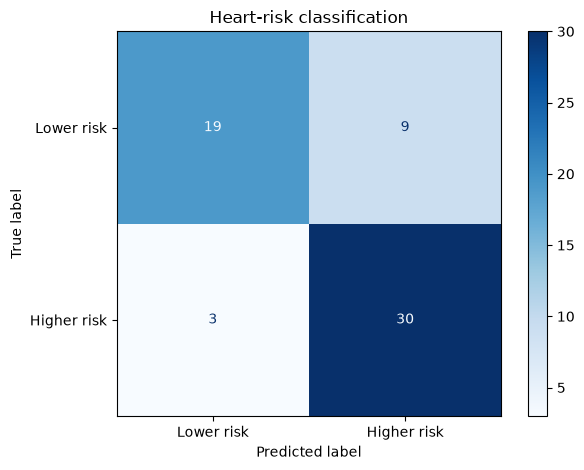

In [7]:
def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack. 
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data.drop(columns=["output"])
    y = data["output"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y,
    )

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000),
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Lower risk", "Higher risk"],
            zero_division=0,
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Lower risk", "Higher risk"],
        cmap="Blues",
    )
    plt.title("Heart-risk classification")
    plt.tight_layout()
    plt.show()

    return model 

data = extract_texts_from_file('resources/heart.csv')
heart_model = heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

Test RMSE: 1071.79 billion USD
Test R²: 0.857


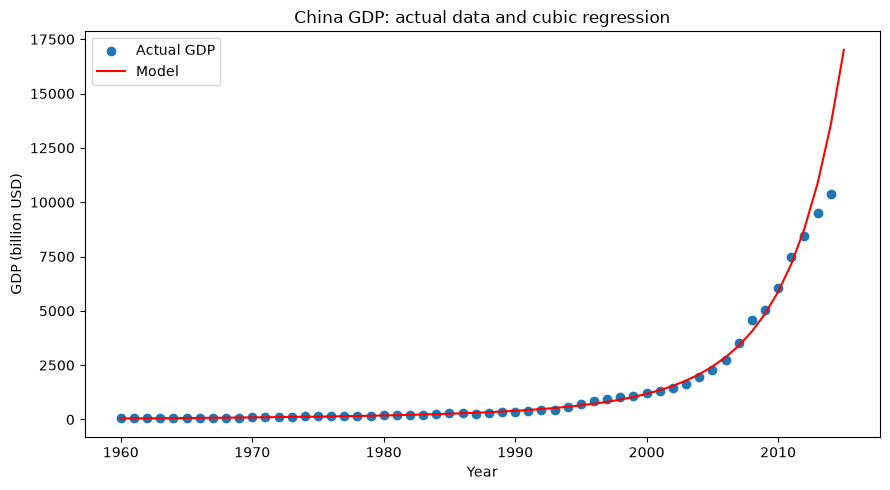

Forecast for 2015: 17014.73 billion USD


In [8]:
def additional(data):
    data = data.dropna(subset=["Year", "Value"]).copy().reset_index(drop=True)
    data["Year"] = pd.to_numeric(data["Year"])
    data["Value"] = pd.to_numeric(data["Value"])

    year_origin = data["Year"].min()
    X = data[["Year"]] - year_origin
    y = np.log1p(data["Value"])

    split_index = int(len(data) * 0.8)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        LinearRegression(),
    )
    model.fit(X_train, y_train)
    test_predictions = np.expm1(model.predict(X_test))
    actual = data["Value"].iloc[split_index:].to_numpy()
    rmse = np.sqrt(mean_squared_error(actual, test_predictions))
    print(f"Test RMSE: {rmse / 1e9:.2f} billion USD")
    print(f"Test R²: {r2_score(actual, test_predictions):.3f}")

    years = pd.DataFrame({
        "Year": np.arange(int(data["Year"].min()), int(data["Year"].max()) + 2)
    })
    years_from_start = years - year_origin
    fitted_values = np.expm1(model.predict(years_from_start))

    plt.figure(figsize=(9, 5))
    plt.scatter(data["Year"], data["Value"] / 1e9, label="Actual GDP")
    plt.plot(years["Year"], fitted_values / 1e9, color="red", label="Model")
    plt.xlabel("Year")
    plt.ylabel("GDP (billion USD)")
    plt.title("China GDP: actual data and cubic regression")
    plt.legend()
    plt.tight_layout()
    plt.show()

    next_year = int(data["Year"].max()) + 1
    next_year_input = pd.DataFrame({"Year": [next_year]}) - year_origin
    forecast = np.expm1(model.predict(next_year_input))[0]
    print(f"Forecast for {next_year}: {forecast / 1e9:.2f} billion USD")
    return model


data = extract_texts_from_file("resources/china_gdp.csv")
additional_model = additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



D:\uni\code\labs\ida-labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Classifying text data...
Dataset columns: ['Id', 'Review', 'Label']


Accuracy: 0.756
              precision    recall  f1-score   support

           1       0.39      0.47      0.42       494
           2       0.18      0.28      0.22       450
           3       0.28      0.29      0.28      1014
           4       0.48      0.18      0.26      3611
           5       0.84      0.94      0.89     15835

    accuracy                           0.76     21404
   macro avg       0.43      0.43      0.41     21404
weighted avg       0.73      0.76      0.73     21404



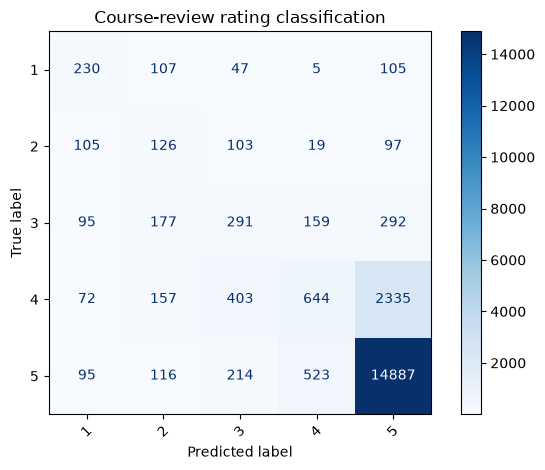

In [9]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues), 
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    # Placeholder for classification logic
    print("Classifying text data...")
    # You can implement your text classification logic here
    text_column = "Review"
    target_column = "Label"

    print("Dataset columns:", df.columns.tolist())
    if text_column not in df.columns or target_column not in df.columns:
        raise KeyError(
            f"Expected columns {text_column!r} and {target_column!r}. "
            "Check the printed column names and update text_column/target_column."
        )

    data = df[[text_column, target_column]].dropna().copy()
    X = data[text_column].astype(str)
    y = data[target_column]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y,
    )

    model = make_pipeline(
        TfidfVectorizer(
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
        ),
        SGDClassifier(
            loss="log_loss",
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            class_weight="balanced",
        ),
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(classification_report(y_test, predictions, zero_division=0))

    display = ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        cmap="Blues",
    )
    display.ax_.tick_params(axis="x", labelrotation=45)
    plt.title("Course-review rating classification")
    plt.tight_layout()
    plt.show()

    return model

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
text_model = classify_text_ml(df)